# Etapa 3: Investigação dos dados, consultas SQL e testes de hipóteses

Todas as consultas exploratórias, gráficos e testes de hipóteses utilizam exclusivamente o período de exploração/treino (`2015–2023`, ou `2000–2023` na série histórica), preservando o conjunto de teste (`2024`) intocado para a avaliação final na Etapa 4.

In [14]:
import sys
from pathlib import Path

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(RAIZ))

import duckdb
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy import stats

from src import config

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

COR = {
    "exp": "#2a78d6", "imp": "#eb6834", "aqua": "#1baf7a", "violeta": "#6250d6",
    "neutro": "#8f8e88", "texto": "#0b0b0b", "texto2": "#52514e",
    "grade": "#e4e3df", "fundo": "#fcfcfb",
}
mpl.rcParams.update({
    "figure.facecolor": COR["fundo"], "axes.facecolor": COR["fundo"], "savefig.facecolor": COR["fundo"],
    "axes.edgecolor": COR["grade"], "axes.labelcolor": COR["texto2"], "axes.titlecolor": COR["texto"],
    "xtick.color": COR["texto2"], "ytick.color": COR["texto2"], "text.color": COR["texto"],
    "axes.grid": True, "grid.color": COR["grade"], "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "font.size": 10,
    "legend.frameon": False, "figure.dpi": 110,
})

P = str(config.PROCESSADOS)
FIG = RAIZ / "reports" / "figuras"
FIG.mkdir(parents=True, exist_ok=True)

diaria = pd.read_parquet(config.PROCESSADOS / "base_diaria_integrada.parquet")
treino = diaria[diaria["periodo"] == "treino"].copy()
horaria_treino = pd.read_parquet(
    config.PROCESSADOS / "intercambio_argentina_horario.parquet",
    filters=[("ano", ">=", 2015), ("ano", "<=", 2023)],
)
print(f"Base diária (treino 2015–2023): {len(treino):,} dias")
print(f"Base horária (treino 2015–2023): {len(horaria_treino):,} registros")

Base diária (treino 2015–2023): 3,287 dias
Base horária (treino 2015–2023): 78,860 registros


## 1. Consultas SQL

### Consulta SQL 1: Perfil horário do intercâmbio

**Pergunta:** *Como o fluxo médio e a frequência de exportação/importação variam ao longo das 24 horas do dia no período de treino (2015–2023)?*

In [15]:
# Consulta SQL 1: agregação horária no período de treino (2015–2023)
q1 = duckdb.sql(f'''
    -- Agrega o intercâmbio por hora do dia para identificar picos intradiários
    SELECT hora,
           COUNT(*) AS horas_obs,
           ROUND(AVG(intercambio_mwmed), 1)                                          AS media_mwmed,
           ROUND(AVG(ABS(intercambio_mwmed)), 1)                                     AS magnitude_media_mwmed,
           ROUND(100.0 * AVG(CASE WHEN sentido = 'exportacao' THEN 1 ELSE 0 END), 1) AS pct_exportando,
           ROUND(100.0 * AVG(CASE WHEN sentido = 'importacao' THEN 1 ELSE 0 END), 1) AS pct_importando,
           ROUND(100.0 * AVG(CASE WHEN sentido = 'sem_fluxo'  THEN 1 ELSE 0 END), 1) AS pct_sem_fluxo
    FROM '{P}/intercambio_argentina_horario.parquet'
    WHERE ano BETWEEN 2015 AND 2023
    GROUP BY hora
    ORDER BY hora
''').df()
q1.T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
hora,0.00,1.00,2.00,3.00,4.00,5.00,6.00,7.00,8.00,9.00,10.00,11.00,12.00,13.00,14.00,15.00,16.00,17.00,18.00,19.00,20.00,21.00,22.00,23.00
horas_obs,"3,282.00","3,286.00","3,286.00","3,286.00","3,286.00","3,286.00","3,286.00","3,286.00","3,286.00","3,286.00","3,286.00","3,286.00","3,286.00","3,286.00","3,286.00","3,286.00","3,286.00","3,286.00","3,286.00","3,286.00","3,286.00","3,286.00","3,286.00","3,286.00"
media_mwmed,59.20,46.90,40.10,35.50,32.90,34.10,49.90,60.70,58.70,61.80,63.60,65.60,67.00,65.40,63.10,61.50,60.00,62.40,65.70,69.90,78.20,81.90,83.30,78.80
magnitude_media_mwmed,243.70,236.70,229.10,222.60,218.40,216.70,221.90,227.20,232.40,242.60,250.80,256.00,258.70,261.60,264.00,266.40,266.30,264.10,262.20,264.00,266.80,267.50,267.70,261.00
pct_exportando,15.50,14.50,14.20,13.90,13.70,13.70,14.30,14.60,14.40,14.60,14.80,14.90,15.00,15.40,15.40,15.60,15.70,15.70,15.40,15.40,15.60,15.70,15.80,15.70
pct_importando,9.70,9.10,8.90,8.80,8.80,8.80,8.80,8.80,9.00,9.30,9.60,9.60,9.80,10.10,10.30,10.40,10.70,10.80,10.30,9.80,9.50,9.30,9.10,9.10
pct_sem_fluxo,74.80,76.40,76.80,77.30,77.50,77.50,76.90,76.60,76.60,76.10,75.60,75.50,75.20,74.40,74.30,74.00,73.60,73.50,74.30,74.80,74.90,75.00,75.10,75.20


**Interpretação (SQL 1):** O intercâmbio apresenta um ciclo intradiário claro: durante a madrugada (01h–05h), o saldo médio e a magnitude caem ao menor patamar do dia, enquanto a partir das 07h há elevação gradual até o pico noturno (19h–22h), acompanhando o horário de ponta de demanda elétrica. A frequência de horas em exportação e importação permanece relativamente estável ao longo do dia, indicando que a hora modula principalmente a intensidade do fluxo, e não a inversão de sentido, o que justifica o atributo hist_media_ult6h_l1 (média das 18h às 23h do dia anterior) na modelagem.

### Consulta SQL 2: Dias úteis, fins de semana e feriados no Brasil e na Argentina

**Pergunta:** *A intensidade e o sentido do intercâmbio diferem entre dias úteis, fins de semana e feriados (separando feriados exclusivos do Brasil, exclusivos da Argentina e simultâneos)?*

In [16]:
# Consulta SQL 2: comparação por tipo de dia e país do feriado (treino 2015–2023)
q2 = duckdb.sql(f'''
    -- Classifica cada dia considerando fim de semana e feriados nacionais em BR e AR
    WITH dias_classificados AS (
        SELECT *,
               CASE
                   WHEN fim_de_semana = 1                               THEN 'Fim de semana'
                   WHEN feriado_br = 1 AND feriado_ar = 1               THEN 'Feriado em ambos'
                   WHEN feriado_br = 1 OR ponto_facultativo_br = 1      THEN 'Feriado/ponto fac. só BR'
                   WHEN feriado_ar = 1                                  THEN 'Feriado só AR'
                   ELSE 'Dia útil (ambos)'
               END AS categoria_dia
        FROM '{P}/base_diaria_integrada.parquet'
        WHERE periodo = 'treino'
    )
    SELECT categoria_dia,
           COUNT(*)                                                                     AS dias,
           ROUND(AVG(intercambio_mwmed), 1)                                             AS saldo_medio_mwmed,
           ROUND(AVG(intercambio_abs_mwmed), 1)                                         AS magnitude_media_mwmed,
           ROUND(AVG(intensidade_horaria_mwmed), 1)                                     AS intensidade_horaria_mwmed,
           ROUND(100.0 * AVG(CASE WHEN sentido_dia = 'exportacao' THEN 1 ELSE 0 END), 1) AS pct_exportacao,
           ROUND(100.0 * AVG(CASE WHEN sentido_dia = 'importacao' THEN 1 ELSE 0 END), 1) AS pct_importacao
    FROM dias_classificados
    GROUP BY categoria_dia
    ORDER BY magnitude_media_mwmed DESC
''').df()
q2

,categoria_dia,dias,saldo_medio_mwmed,magnitude_media_mwmed,intensidade_horaria_mwmed,pct_exportacao,pct_importacao
0,Feriado só AR,91,74.20,342.60,342.60,17.60,14.30
1,Dia útil (ambos),2139,66.60,258.20,258.20,18.40,13.90
2,Fim de semana,940,53.30,228.90,228.90,16.00,10.50
3,Feriado/ponto fac. só BR,88,-43.00,184.80,184.80,10.20,15.90
4,Feriado em ambos,29,84.10,87.90,87.90,6.90,3.40


**Interpretação (SQL 2):** Quando separamos os feriados por país, surgem comportamentos opostos que ficariam escondidos na média agregada (~240,3 MWmed para todos os feriados juntos, vista na seção da H2): Feriado só AR registra a maior magnitude média (342,6 MWmed), acima de Dia útil (ambos) (258,2 MWmed) e Fim de semana (228,9 MWmed). Já Feriado/ponto fac. só BR cai para 184,8 MWmed com saldo médio negativo (-43,0 MWmed, 15,9% de importação), e Feriado em ambos (apenas 29 dias) tem a menor magnitude (87,9 MWmed, com mais de 89% dos dias sem fluxo). Isso indica que feriados no Brasil reduzem a intensidade e aumentam a chance de importação/ausência de fluxo, enquanto feriados exclusivos na Argentina não impedem grandes exportações brasileiras.

### Consulta SQL 3: Sazonalidade mensal e média móvel com CTE e funções de janela

**Pergunta:** *Qual é o padrão sazonal mês a mês do intercâmbio e como a média móvel trimestral e a variação em relação ao mês anterior se comportam?*

In [17]:
# Consulta SQL 3: sazonalidade mensal com CTE e funções de janela (LAG, AVG OVER, RANK)
q3 = duckdb.sql(f'''
    WITH mensal AS (
        SELECT mes,
               COUNT(*)                            AS dias,
               ROUND(AVG(intercambio_mwmed), 1)    AS media_mwmed,
               ROUND(AVG(hidro_ear_pct_se), 1)     AS ear_se_medio_pct,
               ROUND(AVG(preco_cmo_s), 1)          AS cmo_sul_medio,
               ROUND(AVG(clima_ar_tmed), 1)        AS temp_ar_media_c
        FROM '{P}/base_diaria_integrada.parquet'
        WHERE periodo = 'treino'
        GROUP BY mes
    )
    SELECT mes,
           dias,
           media_mwmed,
           -- Média móvel de 3 meses (mês anterior, atual e seguinte)
           ROUND(AVG(media_mwmed) OVER (ORDER BY mes ROWS BETWEEN 1 PRECEDING AND 1 FOLLOWING), 1) AS media_movel_3m,
           -- Diferença em relação ao mês anterior
           ROUND(media_mwmed - LAG(media_mwmed) OVER (ORDER BY mes), 1)                            AS var_mes_anterior,
           RANK() OVER (ORDER BY media_mwmed DESC)                                                 AS rank_exportacao,
           ear_se_medio_pct,
           cmo_sul_medio,
           temp_ar_media_c
    FROM mensal
    ORDER BY mes
''').df()
q3

,mes,dias,media_mwmed,media_movel_3m,var_mes_anterior,rank_exportacao,ear_se_medio_pct,cmo_sul_medio,temp_ar_media_c
0,1,279,68.70,53.30,NaN,6,31.80,239.70,24.50
1,2,254,37.90,75.40,-30.80,7,39.00,310.80,23.60
2,3,279,119.50,95.20,81.60,5,46.40,238.30,21.60
3,4,270,128.20,149.20,8.70,4,50.80,201.20,18.40
4,5,279,199.80,212.50,71.60,3,51.70,185.40,14.30
5,6,270,309.40,266.60,109.60,1,51.40,188.30,11.30
6,7,279,290.50,211.30,-18.90,2,49.10,286.40,10.90
7,8,279,34.00,85.10,-256.50,8,44.70,489.30,12.50
8,9,270,-69.20,-68.20,-103.20,10,39.00,292.40,14.30
9,10,279,-169.50,-149.70,-100.30,11,33.40,246.80,16.80


**Interpretação (SQL 3):** Observa-se uma sazonalidade bem definida, mas com pico antecipado no outono/início do inverno: o saldo médio exportador atinge o auge entre maio e julho (rank 1 em junho com 309,4 MWmed e rank 2 em julho com 290,5 MWmed, quando a média móvel de 3 meses chega a 266,6 MWmed e a EAR SE supera 49–52%). Em agosto, o CMO Sul médio dispara para o maior nível do ano (R$ 489,3/MWh) e o saldo cai para 34,0 MWmed. Na primavera (setembro–novembro), com a EAR SE no piso anual (30,5–39,0%), o fluxo inverte para importação líquida (chegando a -210,3 MWmed em novembro), voltando a ser positivo em janeiro–fevereiro (+68,7 e +37,9 MWmed). Isso confirma a relevância das variáveis cíclicas de calendário (cal_mes, cal_sen_anual, cal_cos_anual) na modelagem.

### Consulta SQL 4: Relação com o clima, extremos térmicos e regimes de temperatura

**Pergunta:** *Como o intercâmbio se comporta em dias de frio intenso na Argentina (HDD), calor intenso no Brasil (CDD) e extremos térmicos (extremo_termico), em comparação a dias termicamente amenos?*

In [18]:
# Consulta SQL 4: associação entre regimes térmicos, extremos e fluxo (treino 2015–2023)
q4 = duckdb.sql(f'''
    WITH regimes AS (
        SELECT *,
               CASE
                   WHEN clima_ar_extremo_frio = 1 AND clima_br_extremo_quente = 1 THEN 'Extremo duplo (Frio AR + Calor BR)'
                   WHEN clima_ar_extremo_frio = 1                                 THEN 'Extremo frio AR (inverno p10)'
                   WHEN clima_ar_extremo_quente = 1                               THEN 'Extremo quente AR (verão p90)'
                   WHEN clima_br_extremo_quente = 1                               THEN 'Extremo quente BR (verão p90)'
                   WHEN clima_br_extremo_frio = 1                                 THEN 'Extremo frio BR (inverno p10)'
                   WHEN clima_ar_hdd > 3                                          THEN 'Frio moderado AR (HDD > 3)'
                   WHEN clima_br_cdd > 3                                          THEN 'Calor moderado BR (CDD > 3)'
                   ELSE 'Dia termicamente ameno'
               END AS regime_termico
        FROM '{P}/base_diaria_integrada.parquet'
        WHERE periodo = 'treino'
    )
    SELECT regime_termico,
           COUNT(*)                                                                      AS dias,
           ROUND(AVG(intercambio_mwmed), 1)                                              AS saldo_medio_mwmed,
           ROUND(AVG(intercambio_abs_mwmed), 1)                                          AS magnitude_media_mwmed,
           ROUND(100.0 * AVG(CASE WHEN sentido_dia = 'exportacao' THEN 1 ELSE 0 END), 1) AS pct_exportacao,
           ROUND(100.0 * AVG(CASE WHEN sentido_dia = 'importacao' THEN 1 ELSE 0 END), 1) AS pct_importacao,
           ROUND(AVG(clima_ar_tmed), 1)                                                  AS temp_ar_c,
           ROUND(AVG(clima_br_tmed), 1)                                                  AS temp_br_c
    FROM regimes
    GROUP BY regime_termico
    ORDER BY saldo_medio_mwmed DESC
''').df()
q4

,regime_termico,dias,saldo_medio_mwmed,magnitude_media_mwmed,pct_exportacao,pct_importacao,temp_ar_c,temp_br_c
0,Extremo frio AR (inverno p10),75,362.70,362.70,37.30,0.00,6.90,17.00
1,Extremo quente AR (verão p90),118,333.80,342.70,34.70,1.70,27.60,22.70
2,Extremo frio BR (inverno p10),72,279.00,315.60,43.10,1.40,11.30,14.10
3,Frio moderado AR (HDD > 3),1036,143.90,286.80,23.50,9.00,11.90,19.00
4,Dia termicamente ameno,1817,-15.10,230.70,12.30,16.50,20.60,21.30
5,Extremo quente BR (verão p90),77,-29.90,33.10,2.60,9.10,23.00,26.10
6,Calor moderado BR (CDD > 3),92,-86.40,87.00,2.20,25.00,21.30,25.50


**Interpretação (SQL 4):** Os regimes térmicos revelam uma assimetria clara entre os dois países: tanto o Extremo frio AR (+362,7 MWmed, 37,3% de exportação, 0% de importação) quanto o Extremo quente AR (+333,8 MWmed, 34,7% de exportação) concentram saldos médios fortemente positivos, sugerindo que extremos de temperatura na Argentina (frio para aquecimento ou calor para refrigeração) elevam a demanda por energia brasileira. Já no Brasil, Calor moderado BR (CDD > 3) (-86,4 MWmed, 25,0% de importação) e Extremo quente BR (-29,9 MWmed, 9,1% de importação) deslocam o saldo para o campo negativo, pois o consumo interno brasileiro sobe e reduz a sobra exportável.

### Consulta SQL 5: Evolução anual, hidrologia e CMO com funções de janela

**Pergunta:** *Como a variação anual do nível dos reservatórios (EAR Sudeste/Sul) e do preço da energia (CMO Sul) acompanha as mudanças de regime entre exportação e importação ao longo de 2015–2023?*

In [19]:
# Consulta SQL 5: agregação anual + comparação interanual e média móvel de 3 anos
q5 = duckdb.sql(f'''
    WITH anual AS (
        SELECT ano,
               ROUND(AVG(intercambio_mwmed), 1)     AS media_mwmed,
               ROUND(AVG(hidro_ear_pct_se), 1)      AS ear_se_pct,
               ROUND(AVG(hidro_ear_pct_s), 1)       AS ear_s_pct,
               ROUND(AVG(hidro_ena_pct_mlt_sin), 1) AS ena_sin_pct_mlt,
               ROUND(AVG(preco_cmo_s), 1)           AS cmo_sul_r_mwh,
               ROUND(AVG(hidro_evt_mwmed_sin), 1)   AS vertimento_sin_mwmed
        FROM '{P}/base_diaria_integrada.parquet'
        WHERE periodo = 'treino'
        GROUP BY ano
    )
    SELECT ano,
           media_mwmed,
           ROUND(media_mwmed - LAG(media_mwmed) OVER (ORDER BY ano), 1)                        AS delta_ano_anterior,
           ROUND(AVG(media_mwmed) OVER (ORDER BY ano ROWS BETWEEN 2 PRECEDING AND CURRENT ROW), 1) AS media_movel_3a,
           ear_se_pct,
           ear_s_pct,
           ena_sin_pct_mlt,
           cmo_sul_r_mwh,
           vertimento_sin_mwmed
    FROM anual
    ORDER BY ano
''').df()
q5

,ano,media_mwmed,delta_ano_anterior,media_movel_3a,ear_se_pct,ear_s_pct,ena_sin_pct_mlt,cmo_sul_r_mwh,vertimento_sin_mwmed
0,2015,19.30,NaN,19.30,29.80,67.70,97.70,550.00,"1,329.90"
1,2016,20.50,1.20,19.90,46.80,86.70,86.60,80.30,"1,760.70"
2,2017,9.70,-10.80,16.50,33.70,57.70,77.00,344.10,"1,489.60"
3,2018,-30.30,-40.00,-0.00,32.70,61.00,84.20,311.50,"1,850.50"
4,2019,-5.20,25.10,-8.60,34.80,52.20,74.30,221.40,"1,921.10"
5,2020,-255.20,-250.00,-96.90,38.60,30.90,76.70,183.30,"2,605.20"
6,2021,-425.00,-169.80,-228.50,25.70,49.60,71.40,535.40,"1,324.20"
7,2022,555.70,980.70,-41.50,55.80,70.50,96.30,31.30,"2,592.20"
8,2023,653.60,97.90,261.40,76.50,88.00,104.10,0.00,"5,798.20"


**Interpretação (SQL 5):** A série anual evidencia uma relação estrutural forte entre oferta hídrica, preço e intercâmbio: em 2020 e 2021, quando a EAR do Sudeste caiu para 38,6% e 25,7% e o CMO do Sul subiu para R$ 183,3/MWh e R$ 535,4/MWh, o Brasil passou a importar fortemente (-255,2 e -425,0 MWmed). Já em 2022 e 2023, com a recuperação dos reservatórios (EAR SE de 55,8% e 76,5%), forte aumento do vertimento turbinável (2.592 e 5.798 MWmed) e queda do CMO para R$ 31,3/MWh e R$ 0,0/MWh, o saldo inverteu para expressiva exportação (+555,7 e +653,6 MWmed).

### Consulta SQL 6: Eventos excepcionais de exportação e importação

**Pergunta:** *Quais foram os 5 meses mais extremos de exportação e os 5 meses mais extremos de importação no período 2015–2023, e quais variáveis explicam esses episódios?*

In [20]:
# Consulta SQL 6: ranqueamento com ROW_NUMBER() para identificar eventos excepcionais
q6 = duckdb.sql(f'''
    WITH meses AS (
        SELECT ano,
               mes,
               ROUND(AVG(intercambio_mwmed), 1)     AS media_mwmed,
               ROUND(MIN(intercambio_mwmed), 1)     AS min_dia_mwmed,
               ROUND(MAX(intercambio_mwmed), 1)     AS max_dia_mwmed,
               ROUND(AVG(hidro_ear_pct_se), 1)      AS ear_se_pct,
               ROUND(AVG(preco_cmo_s), 1)           AS cmo_sul,
               ROUND(AVG(hidro_evt_mwmed_sin), 1)   AS vertimento_sin,
               ROUND(AVG(clima_ar_hdd), 1)          AS ar_hdd_medio
        FROM '{P}/base_diaria_integrada.parquet'
        WHERE periodo = 'treino'
        GROUP BY ano, mes
    ),
    ranqueado AS (
        SELECT *,
               ROW_NUMBER() OVER (ORDER BY media_mwmed DESC) AS rank_exp,
               ROW_NUMBER() OVER (ORDER BY media_mwmed ASC)  AS rank_imp
        FROM meses
    )
    SELECT CASE WHEN rank_exp <= 5 THEN 'Pico Exportação' ELSE 'Pico Importação' END AS evento,
           ano, mes, media_mwmed, min_dia_mwmed, max_dia_mwmed,
           ear_se_pct, cmo_sul, vertimento_sin, ar_hdd_medio
    FROM ranqueado
    WHERE rank_exp <= 5 OR rank_imp <= 5
    ORDER BY media_mwmed DESC
''').df()
q6

,evento,ano,mes,media_mwmed,min_dia_mwmed,max_dia_mwmed,ear_se_pct,cmo_sul,vertimento_sin,ar_hdd_medio
0,Pico Exportação,2022,6,"1,343.70",914.30,"1,743.60",66.20,49.90,"1,114.70",8.60
1,Pico Exportação,2023,3,"1,312.60","1,026.70","1,724.90",80.90,0.00,"12,210.60",0.00
2,Pico Exportação,2023,4,"1,249.00",282.60,"1,812.20",85.30,0.00,"13,468.30",1.10
3,Pico Exportação,2022,12,"1,153.20",217.70,"2,180.80",48.80,0.00,393.00,0.00
4,Pico Exportação,2023,1,"1,134.30",0.50,"1,959.30",62.90,0.00,"9,374.10",0.00
5,Pico Importação,2021,2,-730.80,"-1,605.00",0.00,26.10,165.50,918.40,0.00
6,Pico Importação,2021,8,-903.60,"-2,200.00",0.00,23.90,"2,519.90",340.00,6.20
7,Pico Importação,2021,9,"-1,237.60","-1,895.50",-154.60,18.60,872.70,298.60,3.10
8,Pico Importação,2020,12,"-1,273.40","-2,200.00",0.00,17.10,289.40,379.90,0.10
9,Pico Importação,2020,11,"-1,613.10","-2,200.00",-387.40,20.70,550.10,457.40,0.00


**Interpretação (SQL 6):** Os 5 maiores picos mensais de exportação ocorreram entre 2022 e 2023 (com médias mensais entre 1.134,3 e 1.343,7 MWmed e picos diários acima de 2.180 MWmed), combinando reservatórios cheios (EAR SE entre 48,8% e 85,3%), CMO muito baixo (R$ 0,0 a R$ 49,9/MWh) e alto vertimento turbinável (até 13.468 MWmed em abril/2023). Já os 5 picos de importação concentram-se na crise hídrica de 2020–2021 (médias mensais entre -730,8 e -1.613,1 MWmed), com EAR SE crítica (17,1% a 26,1%) e CMO Sul elevado (de R$ 165,5/MWh até R$ 2.519,9/MWh em agosto/2021).

## 2. Testes estatísticos das hipóteses e gráficos interpretados

In [21]:
# Funções auxiliares para intervalo de confiança via bootstrap
rng = np.random.default_rng(42)

def ic_bootstrap_dif(a, b, n_boot=1000):
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    a, b = a[~np.isnan(a)], b[~np.isnan(b)]
    difs = np.empty(n_boot)
    for i in range(n_boot):
        difs[i] = rng.choice(a, len(a), replace=True).mean() - rng.choice(b, len(b), replace=True).mean()
    return a.mean() - b.mean(), np.percentile(difs, 2.5), np.percentile(difs, 97.5)

def ic_bootstrap_corr(x, y, metodo="spearman", n_boot=1000):
    df_xy = pd.DataFrame({"x": x, "y": y}).dropna()
    xv, yv = df_xy["x"].values, df_xy["y"].values
    fn = stats.spearmanr if metodo == "spearman" else stats.pearsonr
    r_obs, p_val = fn(xv, yv)
    boots = np.empty(n_boot)
    n = len(xv)
    for i in range(n_boot):
        idx = rng.integers(0, n, n)
        boots[i] = fn(xv[idx], yv[idx])[0]
    return r_obs, p_val, np.percentile(boots, 2.5), np.percentile(boots, 97.5)

### Teste da Hipótese H1: Extremos térmicos e temperatura

*Avaliamos se dias com extremos térmicos na Argentina (clima_ar_extremo_termico == 1) ou no Brasil (clima_br_extremo_termico == 1) apresentam distribuição de intercâmbio significativamente diferente dos dias normais, além da associação contínua com clima_ar_hdd e clima_br_cdd.*

,condicao,n_extremo,media_extremo,media_normal,dif_medias,ic95_inf,ic95_sup,p_valor
0,Extremo térmico Argentina,193,345.02,42.48,302.55,218.84,387.78,0.00
1,Extremo frio Argentina,75,362.70,53.18,309.51,187.65,437.90,0.00
2,Extremo quente Argentina,118,333.79,50.06,283.73,179.03,403.14,0.00
3,Extremo térmico Brasil,165,130.06,56.55,73.51,12.08,141.08,0.00


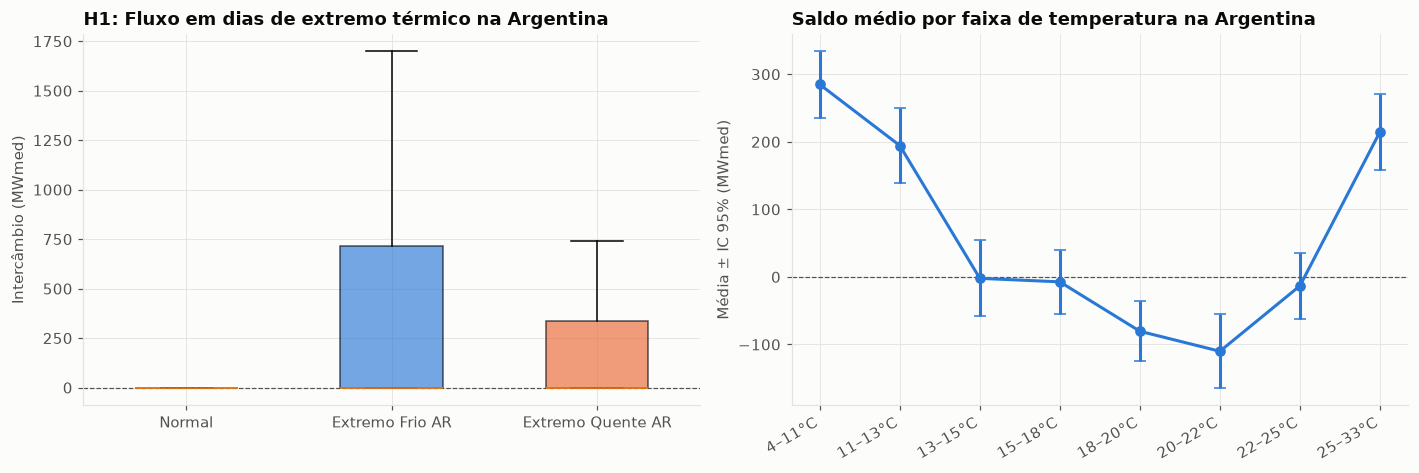

In [22]:
# H1: Mann-Whitney U + IC 95% para extremos térmicos e correlações de Spearman
resultados_h1 = []
for nome, col in [("Extremo térmico Argentina", "clima_ar_extremo_termico"),
                  ("Extremo frio Argentina",    "clima_ar_extremo_frio"),
                  ("Extremo quente Argentina",  "clima_ar_extremo_quente"),
                  ("Extremo térmico Brasil",    "clima_br_extremo_termico")]:
    g1 = treino.loc[treino[col] == 1, "intercambio_mwmed"].dropna()
    g0 = treino.loc[treino[col] == 0, "intercambio_mwmed"].dropna()
    u_stat, p_val = stats.mannwhitneyu(g1, g0, alternative="two-sided")
    dif, ic_inf, ic_sup = ic_bootstrap_dif(g1, g0)
    resultados_h1.append({
        "condicao": nome, "n_extremo": len(g1),
        "media_extremo": g1.mean(), "media_normal": g0.mean(),
        "dif_medias": dif, "ic95_inf": ic_inf, "ic95_sup": ic_sup, "p_valor": p_val,
    })

display(pd.DataFrame(resultados_h1))

# Gráfico 5: H1 — Extremos térmicos e fluxo por faixas de temperatura na Argentina
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.4))

grupos_plot = [
    ("Normal", treino.loc[treino["clima_ar_extremo_termico"] == 0, "intercambio_mwmed"].dropna(), COR["neutro"]),
    ("Extremo Frio AR", treino.loc[treino["clima_ar_extremo_frio"] == 1, "intercambio_mwmed"].dropna(), COR["exp"]),
    ("Extremo Quente AR", treino.loc[treino["clima_ar_extremo_quente"] == 1, "intercambio_mwmed"].dropna(), COR["imp"]),
]
bp = ax1.boxplot([g[1] for g in grupos_plot], tick_labels=[g[0] for g in grupos_plot],
                 patch_artist=True, showfliers=False, widths=0.5)
for patch, (_, _, cor) in zip(bp["boxes"], grupos_plot):
    patch.set_facecolor(cor)
    patch.set_alpha(0.65)
ax1.axhline(0, color=COR["texto2"], lw=0.8, ls="--")
ax1.set_ylabel("Intercâmbio (MWmed)")
ax1.set_title("H1: Fluxo em dias de extremo térmico na Argentina")

bins = pd.qcut(treino["clima_ar_tmed"], q=8, duplicates="drop")
curva_t = treino.groupby(bins, observed=True)["intercambio_mwmed"].agg(["mean", "count", "std"])
se_t = 1.96 * curva_t["std"] / np.sqrt(curva_t["count"])
x_pos = np.arange(len(curva_t))
ax2.errorbar(x_pos, curva_t["mean"], yerr=se_t, fmt="-o", color=COR["exp"], capsize=4, lw=2)
ax2.axhline(0, color=COR["texto2"], lw=0.8, ls="--")
ax2.set_xticks(x_pos)
ax2.set_xticklabels([f"{iv.left:.0f}–{iv.right:.0f}°C" for iv in curva_t.index], rotation=30, ha="right")
ax2.set_ylabel("Média ± IC 95% (MWmed)")
ax2.set_title("Saldo médio por faixa de temperatura na Argentina")

plt.tight_layout()
plt.savefig(FIG / "05_h1_clima_extremos.png", dpi=140, bbox_inches="tight")
plt.show()

**Conclusão (H1):** Os testes de Mann-Whitney e os ICs de 95% confirmam diferença estatisticamente significativa (p < 0,01) para extremos térmicos: na Argentina, tanto o extremo frio (+362,7 MWmed, dif. +309,5) quanto o extremo quente (+333,8 MWmed, dif. +283,7) elevam o saldo exportador em relação aos dias normais (~50–53 MWmed). Contudo, a dispersão dentro de cada grupo permanece ampla, mostrando que o clima atua como modulador de curto prazo, mas não explica sozinho as grandes viradas anuais de regime.

### Teste da Hipótese H2: Feriados e fins de semana

*Testamos se a magnitude diária do fluxo (intercambio_abs_mwmed) varia significativamente entre dia_util, fim_de_semana e feriado no período de treino (2015–2023).*

Kruskal-Wallis (magnitude por tipo_dia): H = 10.26, p = 0.005926


,comparacao,media_grupo,media_dia_util,dif_medias,ic95_inf,ic95_sup,p_valor
0,Fim de semana vs. Dia útil,228.88,258.15,-29.27,-68.75,8.21,0.00
1,Feriado vs. Dia útil,240.31,258.15,-17.84,-90.64,64.16,0.11


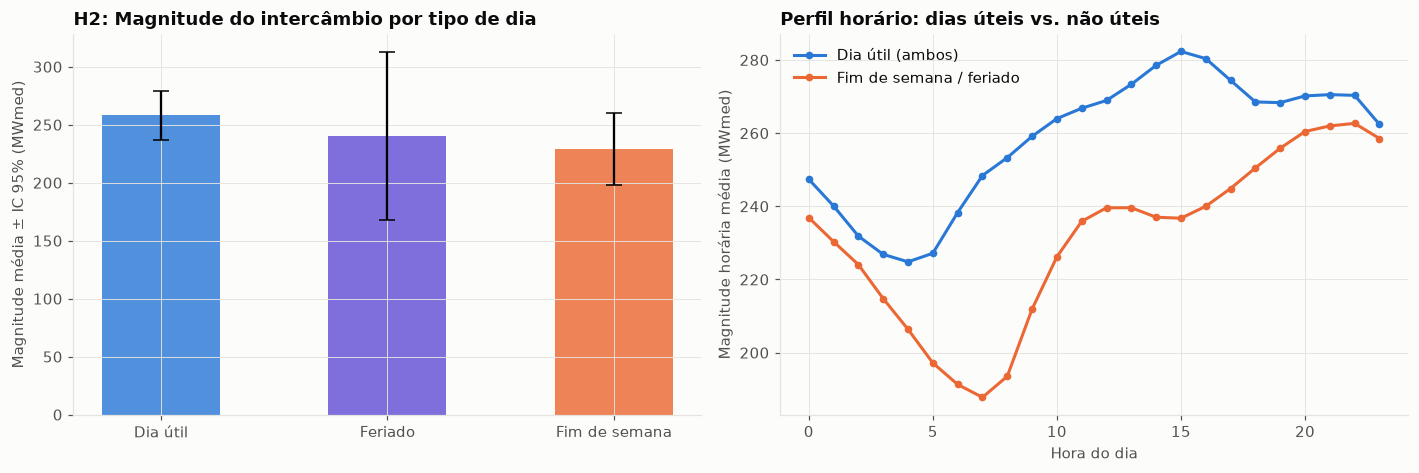

In [23]:
# H2: Kruskal-Wallis + comparações par-a-par com IC 95%
du = treino.loc[treino["tipo_dia"] == "dia_util", "intercambio_abs_mwmed"].dropna()
fds = treino.loc[treino["tipo_dia"] == "fim_de_semana", "intercambio_abs_mwmed"].dropna()
fer = treino.loc[treino["tipo_dia"] == "feriado", "intercambio_abs_mwmed"].dropna()

kw_stat, kw_p = stats.kruskal(du, fds, fer)
print(f"Kruskal-Wallis (magnitude por tipo_dia): H = {kw_stat:.2f}, p = {kw_p:.4g}")

comp_h2 = []
for rotulo, g_comp in [("Fim de semana vs. Dia útil", fds), ("Feriado vs. Dia útil", fer)]:
    u_s, p_v = stats.mannwhitneyu(g_comp, du, alternative="two-sided")
    dif, li, ls = ic_bootstrap_dif(g_comp, du)
    comp_h2.append({"comparacao": rotulo, "media_grupo": g_comp.mean(), "media_dia_util": du.mean(),
                    "dif_medias": dif, "ic95_inf": li, "ic95_sup": ls, "p_valor": p_v})
display(pd.DataFrame(comp_h2))

# Gráfico 6: H2 — Magnitude média com IC 95% por tipo_dia e perfil horário útil vs. não útil
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.4))

cats = [("Dia útil", du, COR["exp"]), ("Feriado", fer, COR["violeta"]), ("Fim de semana", fds, COR["imp"])]
means = [c[1].mean() for c in cats]
errs = [1.96 * c[1].std() / np.sqrt(len(c[1])) for c in cats]
ax1.bar([c[0] for c in cats], means, yerr=errs, color=[c[2] for c in cats], alpha=0.82, capsize=5, width=0.52)
ax1.set_ylabel("Magnitude média ± IC 95% (MWmed)")
ax1.set_title("H2: Magnitude do intercâmbio por tipo de dia")

for label, mask, cor in [
    ("Dia útil (ambos)", horaria_treino["dia_util_ambos"] == 1, COR["exp"]),
    ("Fim de semana / feriado", horaria_treino["dia_util_ambos"] == 0, COR["imp"]),
]:
    perf = horaria_treino.loc[mask].groupby("hora")["intercambio_mwmed"].apply(lambda s: s.abs().mean())
    ax2.plot(perf.index, perf.values, "-o", ms=4, lw=2, color=cor, label=label)
ax2.set_xlabel("Hora do dia")
ax2.set_ylabel("Magnitude horária média (MWmed)")
ax2.set_title("Perfil horário: dias úteis vs. não úteis")
ax2.legend()

plt.tight_layout()
plt.savefig(FIG / "06_h2_calendario_tipo_dia.png", dpi=140, bbox_inches="tight")
plt.show()

**Conclusão (H2):** O teste de Kruskal-Wallis (H = 10,26, p = 0,0059) confirma diferença significativa na magnitude do fluxo entre os tipos de dia, impulsionada principalmente pela queda nos fins de semana (228,88 MWmed) em relação aos dias úteis (258,15 MWmed, Mann-Whitney p < 0,01). Quando todos os feriados são agrupados em uma única categoria (240,31 MWmed), a diferença frente aos dias úteis não é significativa (p = 0,11), justamente porque feriados só na Argentina puxam a magnitude para cima e feriados só no Brasil puxam para baixo (como visto na SQL 2). Isso respalda manter cal_dia_semana, cal_fim_de_semana, cal_feriado_br, cal_feriado_ar e cal_dia_util_ambos separados na modelagem.

### Teste da Hipótese H4: Hidrologia e preço (CMO) vs. variáveis climáticas

*Comparamos a força de associação (correlação de Spearman com IC 95% via bootstrap) entre o bloco de hidrologia/preço (hidro_ear_pct_se, hidro_ear_pct_s, preco_cmo_s, hidro_ena_pct_mlt_sin) e o bloco climático (clima_ar_hdd, clima_br_cdd, clima_ar_tmed, clima_br_se_anom_tmed) frente ao alvo intercambio_mwmed.*

,variavel,bloco,spearman_r,ic95_inf,ic95_sup,p_valor
7,Clima BR SE — Anomalia,Clima,-0.07,-0.11,-0.04,0.00
5,Clima AR — Temp. média,Clima,-0.12,-0.16,-0.09,0.00
6,Clima BR — CDD,Clima,-0.14,-0.17,-0.11,0.00
4,Clima AR — HDD,Clima,0.18,0.15,0.21,0.00
3,ENA SIN (% MLT),Hidrologia/Preço,0.29,0.26,0.32,0.00
1,EAR Sul (%),Hidrologia/Preço,0.43,0.40,0.46,0.00
2,CMO Sul (R$/MWh),Hidrologia/Preço,-0.45,-0.47,-0.42,0.00
0,EAR Sudeste (%),Hidrologia/Preço,0.53,0.50,0.56,0.00


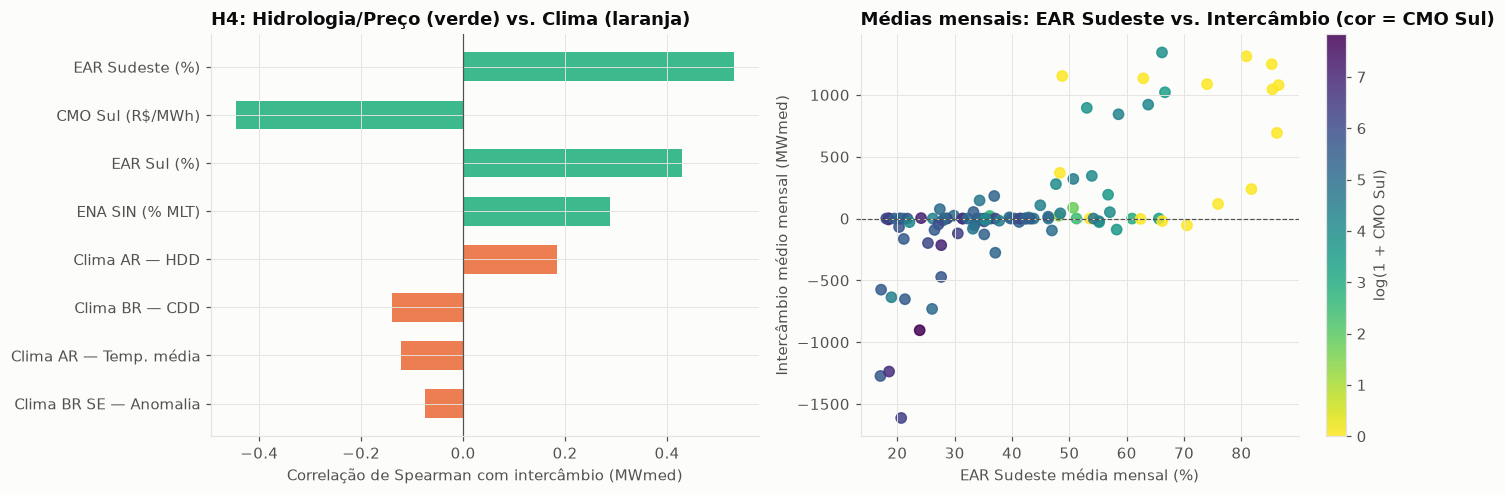

In [24]:
# H4: Correlação de Spearman com IC 95% comparando Hidrologia/CMO vs. Clima
vars_h4 = [
    ("EAR Sudeste (%)",        "hidro_ear_pct_se",      "Hidrologia/Preço"),
    ("EAR Sul (%)",            "hidro_ear_pct_s",       "Hidrologia/Preço"),
    ("CMO Sul (R$/MWh)",       "preco_cmo_s",           "Hidrologia/Preço"),
    ("ENA SIN (% MLT)",        "hidro_ena_pct_mlt_sin", "Hidrologia/Preço"),
    ("Clima AR — HDD",         "clima_ar_hdd",          "Clima"),
    ("Clima AR — Temp. média", "clima_ar_tmed",         "Clima"),
    ("Clima BR — CDD",         "clima_br_cdd",          "Clima"),
    ("Clima BR SE — Anomalia", "clima_br_se_anom_tmed", "Clima"),
]

linhas_h4 = []
for nome, col, bloco in vars_h4:
    r, p, li, ls = ic_bootstrap_corr(treino[col], treino["intercambio_mwmed"], metodo="spearman")
    linhas_h4.append({"variavel": nome, "bloco": bloco, "spearman_r": r, "abs_r": abs(r),
                      "ic95_inf": li, "ic95_sup": ls, "p_valor": p})

df_h4 = pd.DataFrame(linhas_h4).sort_values("abs_r", ascending=True)
display(df_h4[["variavel", "bloco", "spearman_r", "ic95_inf", "ic95_sup", "p_valor"]])

# Gráfico 7: H4 — Comparação de força de associação e dispersão EAR SE vs. Intercâmbio
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6))

cores_h4 = [COR["aqua"] if b == "Hidrologia/Preço" else COR["imp"] for b in df_h4["bloco"]]
y_pos = np.arange(len(df_h4))
ax1.barh(y_pos, df_h4["spearman_r"], color=cores_h4, alpha=0.85, height=0.6)
ax1.axvline(0, color=COR["texto2"], lw=0.8)
ax1.set_yticks(y_pos)
ax1.set_yticklabels(df_h4["variavel"])
ax1.set_xlabel("Correlação de Spearman com intercâmbio (MWmed)")
ax1.set_title("H4: Hidrologia/Preço (verde) vs. Clima (laranja)")

mensal_h4 = treino.groupby(["ano", "mes"], as_index=False)[["hidro_ear_pct_se", "intercambio_mwmed", "preco_cmo_s"]].mean()
sc = ax2.scatter(mensal_h4["hidro_ear_pct_se"], mensal_h4["intercambio_mwmed"],
                 c=np.log1p(mensal_h4["preco_cmo_s"]), cmap="viridis_r", s=45, alpha=0.85)
ax2.axhline(0, color=COR["texto2"], lw=0.8, ls="--")
ax2.set_xlabel("EAR Sudeste média mensal (%)")
ax2.set_ylabel("Intercâmbio médio mensal (MWmed)")
ax2.set_title("Médias mensais: EAR Sudeste vs. Intercâmbio (cor = CMO Sul)")
plt.colorbar(sc, ax=ax2, label="log(1 + CMO Sul)")

plt.tight_layout()
plt.savefig(FIG / "07_h4_hidrologia_cmo_vs_clima.png", dpi=140, bbox_inches="tight")
plt.show()

**Conclusão (H4):** As variáveis de hidrologia e preço (EAR Sudeste, CMO Sul) apresentam correlações substancialmente mais fortes com o intercâmbio do que as variáveis climáticas diárias isoladas. Enquanto o nível dos reservatórios e o custo marginal definem se o Brasil tem excedente barato para exportar ou déficit para importar, o clima e o calendário modulam as variações de curto prazo dentro de cada regime.

### Sazonalidade mensal e persistência temporal

*Visualizando a sazonalidade mensal média com intervalo de confiança e a autocorrelação de curto prazo da série diária (lags 1 a 14), que fundamentam o uso de defasagens e do baseline temporal na Etapa 4.*

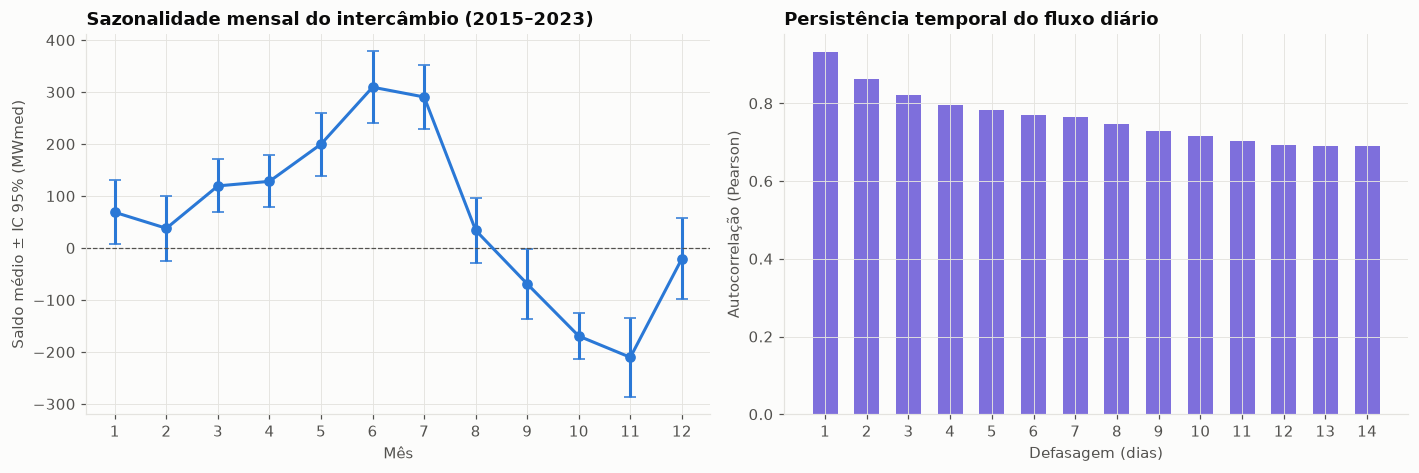

In [25]:
# Gráfico 8: Sazonalidade mensal (IC 95%) e autocorrelação da série diária (treino)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.4))

m_stats = treino.groupby("mes")["intercambio_mwmed"].agg(["mean", "count", "std"])
m_err = 1.96 * m_stats["std"] / np.sqrt(m_stats["count"])
ax1.errorbar(m_stats.index, m_stats["mean"], yerr=m_err, fmt="-o", color=COR["exp"], capsize=4, lw=2)
ax1.axhline(0, color=COR["texto2"], lw=0.8, ls="--")
ax1.set_xticks(range(1, 13))
ax1.set_xlabel("Mês")
ax1.set_ylabel("Saldo médio ± IC 95% (MWmed)")
ax1.set_title("Sazonalidade mensal do intercâmbio (2015–2023)")

lags = range(1, 15)
acfs = [treino["intercambio_mwmed"].autocorr(lag=k) for k in lags]
ax2.bar(lags, acfs, color=COR["violeta"], alpha=0.82, width=0.6)
ax2.set_xticks(list(lags))
ax2.set_xlabel("Defasagem (dias)")
ax2.set_ylabel("Autocorrelação (Pearson)")
ax2.set_title("Persistência temporal do fluxo diário")

plt.tight_layout()
plt.savefig(FIG / "08_sazonalidade_eventos.png", dpi=140, bbox_inches="tight")
plt.show()

## 3. Principais descobertas e orientação para a modelagem

1. **Persistência temporal elevada:** a autocorrelação em lag 1 é muito alta (e decai gradualmente até lag 14), confirmando que o valor de ontem (hist_lag1) e médias móveis recentes (hist_mm7, hist_media_ult6h_l1) são a base da previsão de curto prazo, além de servirem como baseline forte na Etapa 4.
2. **Hidrologia e CMO determinam o regime estrutural (H4):** a forte associação positiva com EAR Sudeste e negativa com CMO Sul explica as inversões plurianuais (importação na crise hídrica de 2020–2021 vs. exportação em 2022–2023). Na Etapa 4, será essencial testar o ganho incremental de incluir esses blocos sem vazamento (usando sempre valores até d−1 e última semana fechada do CMO).
3. **Clima (H1) e calendário (H2) atuam como moduladores de curto prazo:** dias frios na Argentina elevam a tendência exportadora e dias úteis concentram maior magnitude de fluxo do que fins de semana e feriados. Os experimentos comparativos da Etapa 4 (histórico+calendário vs. +feriados vs. +clima vs. todas as fontes) permitirão quantificar o ganho preditivo de cada bloco.